# Assignment: Data Wrangling

### Reading material: `tidy_data.pdf`

**Q1.** This question provides some practice cleaning variables which have common problems.
1. For `./data/airbnb_hw.csv`, clean the `Price` variable as well as you can, and explain the choices you make. How many missing values do you end up with? (Hint: What happens to the formatting when a price goes over 999 dollars, say from 675 to 1,112?)
2. For the Minnesota police use of for data, `./data/mn_police_use_of_force.csv`, clean the `subject_injury` variable, handling the NA's; this gives a value `Yes` when a person was injured by police, and `No` when no injury occurred. What proportion of the values are missing? Is this a concern? Cross-tabulate your cleaned `subject_injury` variable with the `force_type` variable. Are there any patterns regarding when the data are missing?

**Q2.** Go to https://sharkattackfile.net/ and download their dataset on shark attacks (Hint: `GSAF5.xls`).

1. Open the shark attack file using Pandas. It is probably not a csv file, so `read_csv` won't work.
2. Drop any columns that do not contain data.
3. Clean the year variable. Describe the range of values you see. Filter the rows to focus on attacks since 1940. Are attacks increasing, decreasing, or remaining constant over time?
4. Clean the Age variable and make a histogram of the ages of the victims.
5. What proportion of victims are male?
6. Clean the `Type` variable so it only takes three values: Provoked and Unprovoked and Unknown. What proportion of attacks are unprovoked?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student:** Evie McMahan

**Date:** 9/2/2026

### **Q1, Part 1:**

In [83]:
import numpy as np
import pandas as pd

df = pd.read_csv('data/airbnb_hw.csv')

# First look at the dataset
print('Loaded from: src/data/airbnb_hw.csv')
print('Rows, columns:', df.shape)
df.head()

Loaded from: src/data/airbnb_hw.csv
Rows, columns: (30478, 13)


,Host Id,Host Since,Name,Neighbourhood,Property Type,Review Scores Rating (bin),Room Type,Zipcode,Beds,Number of Records,Number Of Reviews,Price,Review Scores Rating
0,5162530,NaN,1 Bedroom in Prime Williamsburg,Brooklyn,Apartment,NaN,Entire home/apt,11249.0,1.0,1,0,145,NaN
1,33134899,NaN,"Sunny, Private room in Bushwick",Brooklyn,Apartment,NaN,Private room,11206.0,1.0,1,1,37,NaN
2,39608626,NaN,Sunny Room in Harlem,Manhattan,Apartment,NaN,Private room,10032.0,1.0,1,1,28,NaN
3,500,6/26/2008,Gorgeous 1 BR with Private Balcony,Manhattan,Apartment,NaN,Entire home/apt,10024.0,3.0,1,0,199,NaN
4,500,6/26/2008,Trendy Times Square Loft,Manhattan,Apartment,95.0,Private room,10036.0,3.0,1,39,549,96.0


At first glance, this dataset looks at the properties of different airbnbs in New York. The dataset has 30,478 rows and 13 columns.  

In [84]:
print(df['Price'].describe()) # Initial price description
df['Price'].unique()


count     30478
unique      511
top         150
freq       1481
Name: Price, dtype: object


<StringArray>
[  '145',    '37',    '28',   '199',   '549',   '149',   '250',    '90',
   '270',   '290',
 ...
 '3,100', '2,486', '3,390', '1,356', '2,599',   '472',   '454',   '328',
   '396',   '291']
Length: 511, dtype: str

The first thing I noticed was that `Price` is an object type.

count    30297.000000
mean       153.357032
std        108.895698
min         10.000000
25%         80.000000
50%        125.000000
75%        192.000000
max        999.000000
Name: Price_cleaned, dtype: float64 

[145.  37.  28. 199. 549. 149. 250.  90. 270. 290. 170.  59.  49.  68.
 285.  75. 100. 150. 700. 125. 175.  40.  89.  95.  99. 499. 120.  79.
 110. 180. 143. 230. 350. 135.  85.  60.  70.  55.  44. 200. 165. 115.
  74.  84. 129.  50. 185.  80. 190. 140.  45.  65. 225. 600. 109.  nan
  73. 240.  72. 105. 155. 160.  42. 132. 117. 295. 280. 159. 107.  69.
 239. 220. 399. 130. 375. 585. 275. 139. 260.  35. 133. 300. 289. 179.
  98. 195.  29.  27.  39. 249. 192. 142. 169. 131. 138. 113. 122. 329.
 101. 475. 238. 272. 308. 126. 235. 315. 248. 128.  56. 207. 450. 215.
 210. 385. 445. 136. 247. 118.  77.  76.  92. 198. 205. 299. 222. 245.
 104. 153. 349. 114. 320. 292. 226. 420. 500. 325. 307.  78. 265. 108.
 123. 189.  32.  58.  86. 219. 800. 335.  63. 229. 425.  67.  87. 158.
 650.

<Axes: >

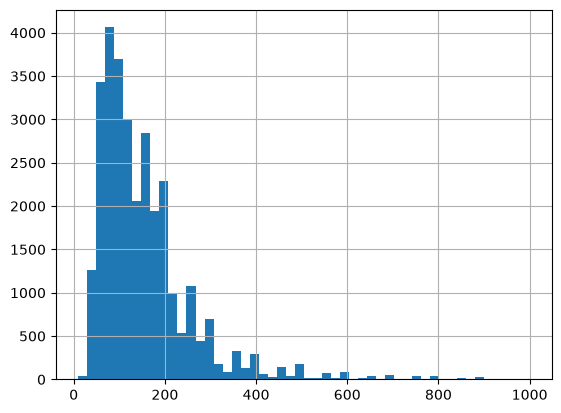

In [85]:
df['Price_cleaned'] = pd.to_numeric(df['Price'], errors='coerce') # Convert Price to numeric
print(df['Price_cleaned'].describe(), '\n') # Post-numeric conversion description
print(df['Price_cleaned'].unique(), '\n')
print(df['Price_cleaned'].value_counts(), '\n')
df['Price_cleaned'].hist(bins = 50) # Show distribution of variable

 After I converted `Price` to numeric, I looked at the unique values, value counts, and distribution to further diagnose the variable. I noticed that the price count was lower (30,297) than before I converted it to a numeric data type (30,478). None of the values over 1,000 show up in the `.unique` analysis, so those values must have gone missing when I converted the variable to numeric.

In [86]:
df['Price_nan'] = df['Price_cleaned'].isnull() # Create new column for missing data
print('Total missing values:', sum(df['Price_nan'])) # Count missing values

df['Price_cleaned'] = df['Price'].str.replace(",","").astype(float) # Remove the commas
df['Price_cleaned'] = pd.to_numeric(df['Price_cleaned'], errors='coerce') # Now, convert the Price without commas to numeric

print('Total missing values after removing commas:', sum(df['Price_cleaned'].isnull()))

Total missing values: 181
Total missing values after removing commas: 0


Great! The commas were the issue that created missing values. I will look one more time at the variable.

In [87]:
print(df['Price_cleaned'].head(), '\n')
print(df['Price_cleaned'].describe(), '\n')
print(df['Price_cleaned'].value_counts())

0    145.0
1     37.0
2     28.0
3    199.0
4    549.0
Name: Price_cleaned, dtype: float64 

count    30478.000000
mean       163.589737
std        197.785454
min         10.000000
25%         80.000000
50%        125.000000
75%        195.000000
max      10000.000000
Name: Price_cleaned, dtype: float64 

Price_cleaned
150.0    1481
100.0    1207
200.0    1059
125.0     889
75.0      873
         ... 
472.0       1
454.0       1
328.0       1
396.0       1
291.0       1
Name: count, Length: 511, dtype: int64


My `Price_cleaned` variable looks clean. It's a numeric type, and there are no missing values. $150 is the most frequent price.

### **Q1, Part 2:**

In [88]:
df = pd.read_csv('data/mn_police_use_of_force.csv')

# First look at the dataset
print('Loaded from: src/data/mn_police_use_of_force.csv')
print('Rows, columns:', df.shape)
df.head()

Loaded from: src/data/mn_police_use_of_force.csv
Rows, columns: (12925, 13)


,response_datetime,problem,is_911_call,primary_offense,subject_injury,force_type,force_type_action,race,sex,age,type_resistance,precinct,neighborhood
0,2016/01/01 00:47:36,Assault in Progress,Yes,DASLT1,NaN,Bodily Force,Body Weight to Pin,Black,Male,20.0,Tensed,1,Downtown East
1,2016/01/01 02:19:34,Fight,No,DISCON,NaN,Chemical Irritant,Personal Mace,Black,Female,27.0,Verbal Non-Compliance,1,Downtown West
2,2016/01/01 02:19:34,Fight,No,DISCON,NaN,Chemical Irritant,Personal Mace,White,Female,23.0,Verbal Non-Compliance,1,Downtown West
3,2016/01/01 02:28:48,Fight,No,PRIORI,NaN,Chemical Irritant,Crowd Control Mace,Black,Male,20.0,Commission of Crime,1,Downtown West
4,2016/01/01 02:28:48,Fight,No,PRIORI,NaN,Chemical Irritant,Crowd Control Mace,Black,Male,20.0,Commission of Crime,1,Downtown West


This is a dataset that describes the instances when police used force. The dataset has 12,925 rows and 13 columns. I already see a lot of NaN's in the `subject_injury` column. 

In [89]:
print(df['subject_injury'].describe(), '\n') # Initial subject_injury description
print(df['subject_injury'].unique(), '\n')
print(df['subject_injury'].value_counts(), '\n')

df['subject_injury_nan'] = df['subject_injury'].isnull() # Create new column for missing data
missing_values_sum = sum(df['subject_injury_nan']) # Sum missing values
proportion_missing = missing_values_sum/(missing_values_sum + df['subject_injury'].count()) # Calculate proportion of missing values

print('Total missing values:', missing_values_sum)
print('Proportion of values missing:', round(proportion_missing*100,2), "%")


count     3077
unique       2
top        Yes
freq      1631
Name: subject_injury, dtype: object 

<StringArray>
[nan, 'No', 'Yes']
Length: 3, dtype: str 

subject_injury
Yes    1631
No     1446
Name: count, dtype: int64 

Total missing values: 9848
Proportion of values missing: 76.19 %


Inspecting `subject_injury`, 76% of values are missing. This is a large proportion of missing values, and it concerns me about the quality of this variable. Other than the nan's, "No" and "Yes" are the only other values, so no string cleaning is needed. I will inspect the patterns in the missing values.

In [90]:
df['subject_injury_cleaned'] = df['subject_injury'].replace(np.nan, 'Missing') # Add missing values so they can be captured in cross tabulation
pd.crosstab(df['subject_injury_cleaned'], df['force_type'], margins = True) # Cross tabulate my cleaned variable with force_type

force_type,Baton,Bodily Force,Chemical Irritant,Firearm,Gun Point Display,Improvised Weapon,Less Lethal,Less Lethal Projectile,Maximal Restraint Technique,Police K9 Bite,Taser,All
subject_injury_cleaned,,,,,,,,,,,,
Missing,2,7051,1421,0,27,74,87,0,170,31,985,9848
No,0,1093,131,2,33,34,0,1,0,2,150,1446
Yes,2,1286,41,0,44,40,0,2,0,44,172,1631
All,4,9430,1593,2,104,148,87,3,170,77,1307,12925


Based on the cross tabulation, the proportion of values that are missing does not appear to be similar across different types of force. Instead, the proportion of missing values by force type is very variable. For example, firearms and less lethal projectiles have no missing values (0 out of 2 and 0 out of 3 missing, respectively), while less lethal and maximal restraint technique only have missing values (87 out of 87 and 170 out of 170 missing, respecively). This supports the hypothesis that the missingness of `subject_injury` differs based on `force_type`. This makes the 76% of values missing even more concerning since the proportion isn't spread evenly across `force_type`, and thus may be biased.

### **Q2:**

In [91]:
df = pd.read_excel('data/GSAF5.xls') 

# First look at the dataset
print('Loaded from: src/data/GSAF5.csv')
print('Rows, columns:', df.shape)
df.head()

Loaded from: src/data/GSAF5.csv
Rows, columns: (7117, 23)


,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,Species,Source,pdf,href formula,href,Case Number,Case Number.1,original order,Unnamed: 21,Unnamed: 22
0,26th August,2026.0,Unprovoked,USA,Hawaii,"Ala Moana Beach Park, Oah'u",Surfing,Unknown Female,F,?,...,Tiger Shark,Keith Cowley: KHON: KITV:,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,23rd August,2026.0,Unprovoked,USA,Florida,Boca Grande (island in the keys),Wading on a sandbar,David Daniel,M,43,...,Large shark,Keith Cowley: Todd Smith: NBC 6: ABC News:,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,19th August,2026.0,Provoked,Reunion Island,Saint-Gilles-les-Baines,Outer Reef Roches Noires,Spearfishiong,Male,M,?,...,Bull shark 2.5m (8.2 ft),Todd Smith: Local Report Zinfos 874:,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,11th August,2026.0,Provoked,Ireland,Waterford,Ardemore County,Fishing,Sebastian Achim,M,27,...,1.5m (5ft) Blue shark,Keith Cowley: David Bargh: Irish Times BBC Met...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,8th August,2026.0,Unprovoked,USA,Maine,Scarborough Beach Park,Operation of Rescue Torpedo,Greg Wilfert,M,71,...,Great White Shark,WGME: CBS News: Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


After opening the shark attack incidence log, I noticed many issues with the dataset. For example, there are unnamed columns (i.e. `Unnamed: 21`), many columns have only NaN's in the first 5 observations, and `age` has question mark values. I will start by inspecting which columns have no data at all.

In [92]:
print(df.notna().sum()) # Print the number of values that aren't NaN in each column

Date              7117
Year              7115
Type              7099
Country           7067
State             6630
Location          6550
Activity          6534
Name              6899
Sex               6539
Age               4123
Injury            7081
Fatal Y/N         6556
Time              3590
Species           3986
Source            7097
pdf               6799
href formula      6794
href              6796
Case Number       6798
Case Number.1     6797
original order    6799
Unnamed: 21          1
Unnamed: 22          2
dtype: int64


The two "unnamed" columns only have 1 to 2 non-NA values, so I am going to inspect them further.

In [93]:
# Inspect the values and their corresponding counts in the "unnamed" columns
print(df['Unnamed: 21'].value_counts(), '\n')
print(df['Unnamed: 22'].value_counts())

df_cleaned = df.drop(columns = ['Unnamed: 21', 'Unnamed: 22']) # Drop the two columns
print(df_cleaned.shape)
df_cleaned.head()

Unnamed: 21
stopped here    1
Name: count, dtype: int64 

Unnamed: 22
Teramo             1
change filename    1
Name: count, dtype: int64
(7117, 21)


,Date,Year,Type,Country,State,Location,Activity,Name,Sex,Age,...,Fatal Y/N,Time,Species,Source,pdf,href formula,href,Case Number,Case Number.1,original order
0,26th August,2026.0,Unprovoked,USA,Hawaii,"Ala Moana Beach Park, Oah'u",Surfing,Unknown Female,F,?,...,N,1330hrs,Tiger Shark,Keith Cowley: KHON: KITV:,NaN,NaN,NaN,NaN,NaN,NaN
1,23rd August,2026.0,Unprovoked,USA,Florida,Boca Grande (island in the keys),Wading on a sandbar,David Daniel,M,43,...,N,1700hrs,Large shark,Keith Cowley: Todd Smith: NBC 6: ABC News:,NaN,NaN,NaN,NaN,NaN,NaN
2,19th August,2026.0,Provoked,Reunion Island,Saint-Gilles-les-Baines,Outer Reef Roches Noires,Spearfishiong,Male,M,?,...,N,?,Bull shark 2.5m (8.2 ft),Todd Smith: Local Report Zinfos 874:,NaN,NaN,NaN,NaN,NaN,NaN
3,11th August,2026.0,Provoked,Ireland,Waterford,Ardemore County,Fishing,Sebastian Achim,M,27,...,N,1615hrs,1.5m (5ft) Blue shark,Keith Cowley: David Bargh: Irish Times BBC Met...,NaN,NaN,NaN,NaN,NaN,NaN
4,8th August,2026.0,Unprovoked,USA,Maine,Scarborough Beach Park,Operation of Rescue Torpedo,Greg Wilfert,M,71,...,N,1300hrs,Great White Shark,WGME: CBS News: Keith Cowley,NaN,NaN,NaN,NaN,NaN,NaN


I dropped `Unnamed: 21` and `Unnamed: 22` because they didn't have meaningful data within them. They both had either 1 or 2 lines of meaningless data that weren't tied to any variables or observations.

In [94]:
print(df_cleaned['Year'].describe(), '\n') # Initial Year description
print(df_cleaned['Year'].unique(), '\n')
print('NaN sum:', sum(df_cleaned['Year'].isna())) # Determine how many NaN values Year has

count    7115.000000
mean     1936.549122
std       269.943193
min         0.000000
25%      1948.000000
50%      1987.000000
75%      2010.000000
max      2026.000000
Name: Year, dtype: float64 

[2026. 2025. 2024. 2023. 2022. 2021. 2020. 2019. 2018. 2017.   nan 2016.
 2015. 2014. 2013. 2012. 2011. 2010. 2009. 2008. 2007. 2006. 2005. 2004.
 2003. 2002. 2001. 2000. 1999. 1998. 1997. 1996. 1995. 1984. 1994. 1993.
 1992. 1991. 1990. 1989. 1969. 1988. 1987. 1986. 1985. 1983. 1982. 1981.
 1980. 1979. 1978. 1977. 1976. 1975. 1974. 1973. 1972. 1971. 1970. 1968.
 1967. 1966. 1965. 1964. 1963. 1962. 1961. 1960. 1959. 1958. 1957. 1956.
 1955. 1954. 1953. 1952. 1951. 1950. 1949. 1948. 1848. 1947. 1946. 1945.
 1944. 1943. 1942. 1941. 1940. 1939. 1938. 1937. 1936. 1935. 1934. 1933.
 1932. 1931. 1930. 1929. 1928. 1927. 1926. 1925. 1924. 1923. 1922. 1921.
 1920. 1919. 1918. 1917. 1916. 1915. 1914. 1913. 1912. 1911. 1910. 1909.
 1908. 1907. 1906. 1905. 1904. 1903. 1902. 1901. 1900. 1899. 1898. 1897.


The range of values in `Year` is from 0 to 2026, with 75% occuring after 1948. There are definitely outliers, especially the values 0, 5, and 77. The instructions say to filter the rows to focus on attacks since 1940. Since there are only two NaN values, I am going to keep them and convert the rest of the Year values to integers.

count         5581.0
mean     1992.668518
std        24.311209
min           1940.0
25%           1970.0
50%           2000.0
75%           2013.0
max           2026.0
Name: Year, dtype: Float64 

Year
1940     24
1941     27
1942     41
1943     28
1944     31
       ... 
2022     98
2023    109
2024     52
2025     69
2026     53
Name: count, Length: 87, dtype: Int64


<Axes: xlabel='Year'>

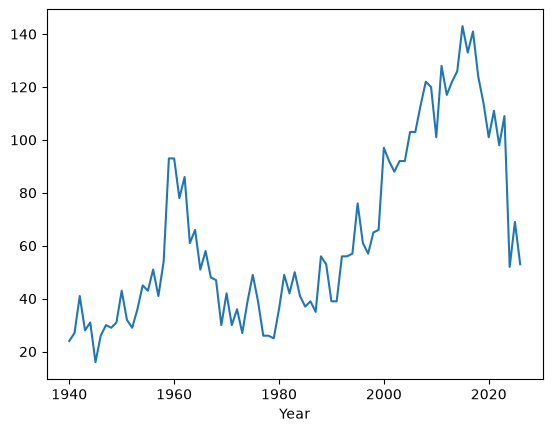

In [95]:
import matplotlib.pyplot as plt

df_cleaned['Year'] = df_cleaned['Year'].astype('Int64') # Remove the decimal place
df_cleaned = df_cleaned.loc[df_cleaned['Year'] >= 1940] # Filter attacks since 1940

print(df_cleaned['Year'].describe(), '\n')
print(df_cleaned['Year'].value_counts().sort_index())

df_counts = df_cleaned['Year'].value_counts().sort_index() # Create variable of value counts by year, sorted
df_counts.plot(kind='line') # Plot a line chart


Attacks in general have increased over time, although not linearly. I plotted a quick line chart to visualize the relationship between year and the number of shark attacks. Attacks per year peaked around 1960 and then again around 2018.

In [96]:
print(df_cleaned['Age'].dtype) # Initial Age description
print(df_cleaned['Age'].describe(), '\n')
print(df_cleaned['Age'].unique())
print(df_cleaned['Age'].value_counts(), '\n')

print('NaN sum:', sum(df_cleaned['Age'].isna())) # Determine how many NaN values Age has
print('Occurances of "or":', df_cleaned['Age'].str.count('or').sum()) # Number of times "or" is in a value in Age
print('Occurances of "and":', df_cleaned['Age'].str.count('and').sum()) 
print('Occurances of "&":', df_cleaned['Age'].str.count('&').sum()) 
print('Occurances of "months":', df_cleaned['Age'].str.count('months').sum()) 




object
count     3804
unique     239
top         16
freq        80
Name: Age, dtype: int64 

['?' '43' '27' '71' '21' '69' '31' '13' '12' '17' '35' "20's" '19' '11'
 '20' '38' '39' '16' '22' '30+' "50's" '55' '26' '56' '24' '25' '61' '40'
 '14' '50+' '54' '48' '57' '8' '63' '9' '7' '85' '18' '66' '37' '42' '45'
 '30' '60' '40+' '29' 35 58 29 24 20 55 17 12 37 36 23 40 28 69 48 '60+'
 57 45 61 27 38 16 68 33 30 15 41 14 43 26 'Middle age' 18 21 49 25 46 19
 65 64 nan '46' '32' '10' '64' '62' '15' '52' '44' '47' '59' '50' '34'
 '30s' '20/30' '65' '20s' '77' '49' '!2' '73' '50s' '58' '67' '6' '41'
 '53' '68' '51' 39 51 10 13 60 '40s' 62 'teen' 8 22 32 56 'Teen' 42 50 'M'
 9 31 11 34 '!6' '!!' 47 7 71 59 53 54 75 '45 and 15' 73 52 70 4 63 44
 '28 & 22' '22, 57, 31' '60s' 67 74 '9 & 60' 'a minor' 6 3 82 '40?' 66 72
 '23' '36' '70' '18 months' '28' '33' '74' '3' '28 & 26' '5' '86'
 '18 or 20' '12 or 13' '46 & 34' '28, 23 & 30' 'Teens' 77 '36 & 26'
 '8 or 10' 84 '\xa0 ' ' ' '30 or 36' '6½' '2

I need to convert `Age` to a numeric variable, but first I have to decide what to do with the messy values. There are many problems here. Some values have multiple ages, some just have age descriptions, and others are completely unknown. I sorted through the column to determine how many instances of "or", "and", "&", and "months" there are. Since there are only 47 combined values with a variation of these words, I will coerce every messy value to be NaN. Question marks and age descriptions (such as elderly) should also become NaN.

count    3645.000000
mean       28.638409
std        14.843747
min         1.000000
25%        17.000000
50%        25.000000
75%        38.000000
max        87.000000
Name: Age, dtype: float64 

[nan 43. 27. 71. 21. 69. 31. 13. 12. 17. 35. 19. 11. 20. 38. 39. 16. 22.
 55. 26. 56. 24. 25. 61. 40. 14. 54. 48. 57.  8. 63.  9.  7. 85. 18. 66.
 37. 42. 45. 30. 60. 29. 58. 36. 23. 28. 68. 33. 15. 41. 49. 46. 65. 64.
 32. 10. 62. 52. 44. 47. 59. 50. 34. 77. 73. 67.  6. 53. 51. 75. 70.  4.
 74.  3. 82. 72.  5. 86. 84. 87.  1. 81. 78.]
Age
17.0    151
20.0    141
15.0    141
19.0    137
18.0    137
       ... 
84.0      1
87.0      1
1.0       1
81.0      1
78.0      1
Name: count, Length: 82, dtype: int64 



<Axes: >

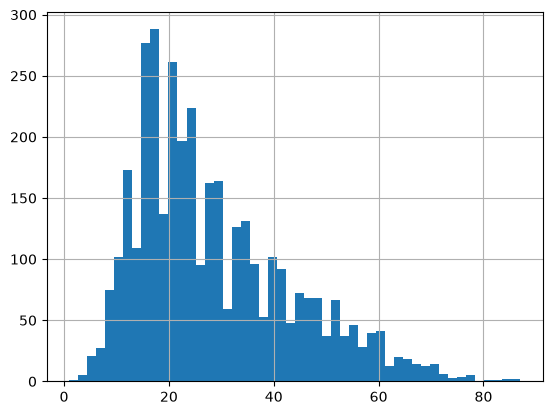

In [97]:
df_cleaned['Age'] = pd.to_numeric(df_cleaned['Age'], errors='coerce') # Convert the object type to numeric, make all messy data NaN
df_cleaned['Age_NaN'] = df_cleaned['Age'].isnull() # Preserve countable record of null values

print(df_cleaned['Age'].describe(), '\n')
print(df_cleaned['Age'].unique())
print(df_cleaned['Age'].value_counts(), '\n')
df_cleaned['Age'].hist(bins = 50) # Create histogram

Now that the `Age` variable is clean, you can see the distribution on the histogram. No age is spared from a shark attack, as ages span from 1 to 87 years old. The most frequent age to be attacked by a shark is 17, and then the value count declines as you age.

In [98]:
print(df_cleaned['Sex'].describe(), '\n') # Initial Sex description
print(df_cleaned['Sex'].unique(), '\n')
print(df_cleaned['Sex'].value_counts(), '\n')
print('NaN sum:', sum(df_cleaned['Sex'].isna())) # Determine how many NaN values Sex has

count     5130
unique      10
top          M
freq      4384
Name: Sex, dtype: object 

<StringArray>
['F', 'M', 'M ', 'M F', '?', 'F ', nan, ' M', 'm', 'lli', 'M x 2']
Length: 11, dtype: str 

Sex
M        4384
F         730
M           7
?           2
F           2
M F         1
 M          1
m           1
lli         1
M x 2       1
Name: count, dtype: int64 

NaN sum: 451


I will drop the rows with multiple victims, such as "M F" and "M x 2", to be consist with how I treated `Age` (made them NaN). I will also make "?", and "lli" values NaN. I will clean the other male values to have no spaces before/after and follow the same capitalization as "M".

In [99]:
df_cleaned['Sex'] = df_cleaned['Sex'].replace(['M F', 'lli', 'M x 2', '?'], np.nan) # Replace messy values with NaN
df_cleaned['Sex'] = df_cleaned['Sex'].str.strip() # Remove extra spaces around Sex values
df_cleaned['Sex'] = df_cleaned['Sex'].str.upper() # Make Sex values uppercase

print(df_cleaned['Sex'].value_counts(), '\n')
print('Proportion of male victims:', round(df_cleaned['Sex'].value_counts(normalize=True)['M']*100,2), "%") # Calculate the relative frequency of the "M" value 


Sex
M    4393
F     732
Name: count, dtype: int64 

Proportion of male victims: 85.72 %


After my cleaning, I found the proportion of male victims to be about 85%. That is a super interesting finding. 

In [100]:
print(df_cleaned['Type'].describe(), '\n') # Initial Type description
print(df_cleaned['Type'].unique(), '\n')
print(df_cleaned['Type'].value_counts(), '\n')
print('NaN sum:', sum(df_cleaned['Type'].isna())) # Determine how many NaN values Type has

count           5567
unique            14
top       Unprovoked
freq            4161
Name: Type, dtype: object 

<StringArray>
[         'Unprovoked',            'Provoked',        'Questionable',
          'UNprovoked',          'unprovoked',           ' Provoked',
          'Watercraft',        'Sea Disaster',                   nan,
                   '?',         'Unconfirmed',          'Unverified',
             'Invalid', 'Under investigation',                'Boat']
Length: 15, dtype: str 

Type
Unprovoked             4161
Provoked                526
Invalid                 402
Watercraft              280
Sea Disaster            156
Questionable             27
Boat                      7
 Provoked                 2
UNprovoked                1
unprovoked                1
?                         1
Unconfirmed               1
Unverified                1
Under investigation       1
Name: count, dtype: int64 

NaN sum: 14


In order to make all the values fall into Provoked, Unprovoked, and Unknown, I will first remove the extra spaces and capitalize the values. Then I will impute all values other than Provoked and Unprovoked to be Unknown. I didn't make a separate impute variable since df already has been copied via `df_cleaned`.

In [101]:
df_cleaned['Type'] = df_cleaned['Type'].str.strip() # Remove extra spaces
df_cleaned['Type'] = df_cleaned['Type'].str.capitalize() # Make values capitalized

print(df_cleaned['Type'].value_counts(), '\n')

impute_value = 'Unknown'
df_cleaned['Type'] = np.where(df_cleaned['Type'].isin(['Provoked','Unprovoked']), df_cleaned['Type'],impute_value) # For any value that isn't "Provoked" or "Unprovoked", fill in "Unknown"
print(df_cleaned['Type'].value_counts(), '\n')

print('Proportion of unprovoked attacks:', round(df_cleaned['Type'].value_counts(normalize = True)['Unprovoked']*100,2), "%")



Type
Unprovoked             4163
Provoked                528
Invalid                 402
Watercraft              280
Sea disaster            156
Questionable             27
Boat                      7
?                         1
Unconfirmed               1
Unverified                1
Under investigation       1
Name: count, dtype: int64 

Type
Unprovoked    4163
Unknown        890
Provoked       528
Name: count, dtype: int64 

Proportion of unprovoked attacks: 74.59 %


Approximately 75% of attacks are unprovoked.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [102]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]